# ERA V5 · Session 13 — Reversible training of a ~20M LLM on 50M tokens

1. Baseline: standard residual GPT, fixed batch.
2. Reversible, same batch: **midpoint** and **symplectic Euler** variants.
3. Best variant again with blocks in fp32 (exact rebuild check).
4. Best reversible variant pushed to the true max batch.
5. Report: final loss, tokens/s, peak memory, reconstruction error, auto-generated findings.

Runtime → Change runtime type → GPU. Uses the Colab GPU automatically (bf16 on Ampere+, fp16 + GradScaler on T4).
Byte-level vocab (256) so logits don't swamp activation memory — the thing reversibility changes is visible.

In [1]:
import time, gc, math
import numpy as np, torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt

DEV = "cuda" if torch.cuda.is_available() else "cpu"
assert DEV == "cuda", "Enable a GPU runtime"
AMP_DTYPE = torch.bfloat16 if torch.cuda.get_device_capability()[0] >= 8 else torch.float16
print(torch.cuda.get_device_name(), "| amp:", AMP_DTYPE)

def sync(): torch.cuda.synchronize()

TOKENS     = 50_000_000     # training tokens per run (lower for a quick test)
VAL_TOKENS = 1_000_000
V, T, D, L, NH = 256, 512, 384, 12, 6   # bytes vocab, context, width, layers, heads
BATCH      = 32             # fixed batch for runs 1-3
LR, WARMUP = 1e-3, 200
H = {"midpoint": 0.25, "euler": 0.5}    # step sizes (starting points, tune)

Tesla T4 | amp: torch.float16


## Data: TinyStories, streamed until 51M bytes

In [2]:
from datasets import load_dataset
need, buf, n = TOKENS + VAL_TOKENS, [], 0
for ex in load_dataset("roneneldan/TinyStories", split="train", streaming=True):
    b = (ex["text"].strip() + "\n\n").encode("utf-8")
    buf.append(b); n += len(b)
    if n >= need: break
data = torch.from_numpy(np.frombuffer(b"".join(buf), dtype=np.uint8).copy()).to(DEV)
train_data, val_data = data[:-VAL_TOKENS], data[-VAL_TOKENS:]
print(f"train {len(train_data)/1e6:.1f}M bytes | val {len(val_data)/1e6:.1f}M bytes")

OFF = torch.arange(T + 1, device=DEV)
def get_batch(src, b, gen=None):
    ix = torch.randint(len(src) - T - 1, (b,), device=DEV, generator=gen)
    chunk = src[ix[:, None] + OFF].long()
    return chunk[:, :-1], chunk[:, 1:]

README.md:   0%|          | 0.00/1.06k [00:00<?, ?B/s]

train 50.0M bytes | val 1.0M bytes


## Model
- `Block.forward` returns **f(p)** = block(p) − p (the residual update only).
- Standard: `p = p + f(p)`, every layer's activations kept by autograd.
- **Midpoint**: `p[l+1] = p[l-1] + 2h·f(p[l])` → inverse `p[l-1] = p[l+1] − 2h·f(p[l])`.
- **Symplectic Euler** (two streams x, v): `v += h·f(x); x += h·v` → inverse `x -= h·v; v -= h·f(x)`.
- `RevStack` keeps only the final two states; backward rebuilds each layer's input, then backprops that one layer.

In [3]:
class Block(nn.Module):
    def __init__(self):
        super().__init__()
        self.ln1, self.ln2 = nn.LayerNorm(D), nn.LayerNorm(D)
        self.qkv  = nn.Linear(D, 3 * D, bias=False)
        self.proj = nn.Linear(D, D, bias=False)
        self.fc   = nn.Linear(D, 4 * D, bias=False)
        self.out  = nn.Linear(4 * D, D, bias=False)

    def attn(self, x):
        B, Tt, C = x.shape
        q, k, v = self.qkv(x).view(B, Tt, 3, NH, C // NH).permute(2, 0, 3, 1, 4)
        y = F.scaled_dot_product_attention(q, k, v, is_causal=True)
        return self.proj(y.transpose(1, 2).reshape(B, Tt, C))

    def forward(self, p):                      # f(p), no residual
        a = self.attn(self.ln1(p))
        return a + self.out(F.gelu(self.fc(self.ln2(p + a))))


REV_FP32 = False                               # True: reversible blocks run in fp32 (exact rebuild)
def fb(blk, x):
    if REV_FP32:
        with torch.autocast("cuda", enabled=False):
            return blk(x.float())
    return blk(x)

def rev_fwd(mode, h, blk, s0, s1):
    if mode == "midpoint":                     # (p[l-1], p[l]) -> (p[l], p[l+1])
        return s1, s0 + 2 * h * fb(blk, s1)
    v = s1 + h * fb(blk, s0)                   # euler: (x, v) -> (x', v')
    return s0 + h * v, v

def rev_inv(mode, h, blk, s0, s1):             # exact inverse of rev_fwd
    if mode == "midpoint":                     # (p[l], p[l+1]) -> (p[l-1], p[l])
        return s1 - 2 * h * fb(blk, s0), s0
    x = s0 - h * s1
    return x, s1 - h * fb(blk, x)


class RevStack(torch.autograd.Function):
    @staticmethod
    @torch.amp.custom_fwd(device_type="cuda")
    def forward(ctx, s0, s1, mode, h, blocks, *params):
        with torch.no_grad():
            for blk in blocks:
                s0, s1 = rev_fwd(mode, h, blk, s0, s1)
        ctx.mode, ctx.h, ctx.blocks = mode, h, blocks
        ctx.save_for_backward(s0, s1)          # the ONLY stored activations
        return s1 if mode == "midpoint" else s0

    @staticmethod
    @torch.amp.custom_bwd(device_type="cuda")
    def backward(ctx, gy):
        s0, s1 = ctx.saved_tensors
        mode, h, blocks = ctx.mode, ctx.h, ctx.blocks
        g0, g1 = (torch.zeros_like(s0), gy) if mode == "midpoint" else (gy, torch.zeros_like(s1))
        pgrads = []
        for blk in reversed(blocks):
            ps = list(blk.parameters())
            if mode == "midpoint":             # state (p[l], p[l+1]), grads (g0, g1)
                z = s0.detach().requires_grad_()
                with torch.enable_grad(): f = fb(blk, z)
                s0, s1 = s1 - 2 * h * f.detach(), s0            # rebuild p[l-1]
                gz, *gp = torch.autograd.grad(f, [z] + ps, (2 * h * g1).to(f.dtype))
                g0, g1 = g1, g0 + gz
            else:                              # state (x[l+1], v[l+1]), grads (gx, gv)
                s0 = s0 - h * s1                                  # rebuild x[l]
                z = s0.detach().requires_grad_()
                with torch.enable_grad(): f = fb(blk, z)
                s1 = s1 - h * f.detach()                          # rebuild v[l]
                g1 = g1 + h * g0
                gz, *gp = torch.autograd.grad(f, [z] + ps, (h * g1).to(f.dtype))
                g0 = g0 + gz
            pgrads = gp + pgrads
        return (g0, g1, None, None, None, *pgrads)


class GPT(nn.Module):
    def __init__(self, mode):                  # "std" | "midpoint" | "euler"
        super().__init__()
        self.mode = mode
        self.tok, self.pos = nn.Embedding(V, D), nn.Embedding(T, D)
        self.blocks = nn.ModuleList(Block() for _ in range(L))
        self.lnf  = nn.LayerNorm(D)
        self.head = nn.Linear(D, V, bias=False)
        self.head.weight = self.tok.weight
        self.apply(self._init)

    @staticmethod
    def _init(m):                              # GPT-style: first-step loss ~ ln(256) = 5.5
        if isinstance(m, (nn.Linear, nn.Embedding)):
            nn.init.normal_(m.weight, std=0.02)

    def embed(self, idx):
        return self.tok(idx) + self.pos(torch.arange(idx.shape[1], device=idx.device))

    def forward(self, idx):
        x = self.embed(idx)
        if self.mode == "std":
            for b in self.blocks: x = x + b(x)
        else:
            s1 = x if self.mode == "midpoint" else torch.zeros_like(x)
            params = [p for b in self.blocks for p in b.parameters()]
            x = RevStack.apply(x, s1, self.mode, H[self.mode], self.blocks, *params)
        return self.head(self.lnf(x))

print(f"params: {sum(p.numel() for p in GPT('std').parameters())/1e6:.1f}M")

params: 21.5M


## Training, eval, reconstruction check, max-batch probe

In [4]:
def lr_at(step, steps):
    w = min(WARMUP, steps // 10)
    if step < w: return LR * (step + 1) / w
    return 0.1 * LR + 0.9 * LR * 0.5 * (1 + math.cos(math.pi * (step - w) / max(1, steps - w)))

def make(mode):
    torch.manual_seed(0)
    model = GPT(mode).to(DEV)
    opt = torch.optim.AdamW(model.parameters(), lr=LR, betas=(0.9, 0.95), weight_decay=0.0, fused=True)
    scaler = torch.amp.GradScaler("cuda", enabled=(AMP_DTYPE == torch.float16))
    return model, opt, scaler

def train_step(model, opt, scaler, b, lr):
    for g in opt.param_groups: g["lr"] = lr
    x, y = get_batch(train_data, b)
    with torch.autocast("cuda", dtype=AMP_DTYPE):
        loss = F.cross_entropy(model(x).float().view(-1, V), y.reshape(-1))
    opt.zero_grad(set_to_none=True)
    scaler.scale(loss).backward()
    scaler.unscale_(opt)
    torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
    scaler.step(opt); scaler.update()
    return loss.detach()

@torch.no_grad()
def val_loss(model, n=50, b=16):
    gen = torch.Generator(device=DEV).manual_seed(123)
    model.eval(); tot = 0.0
    for _ in range(n):
        x, y = get_batch(val_data, b, gen)
        with torch.autocast("cuda", dtype=AMP_DTYPE):
            tot += F.cross_entropy(model(x).float().view(-1, V), y.reshape(-1)).item()
    model.train()
    return tot / n

@torch.no_grad()
def recon_error(model):
    # run the stack forward, then invert it back to the input; relative max error
    x, _ = get_batch(val_data, 8)
    with torch.autocast("cuda", dtype=AMP_DTYPE):
        e = model.embed(x)
        s0, s1 = e, (e if model.mode == "midpoint" else torch.zeros_like(e))
        for blk in model.blocks: s0, s1 = rev_fwd(model.mode, H[model.mode], blk, s0, s1)
        for blk in reversed(model.blocks): s0, s1 = rev_inv(model.mode, H[model.mode], blk, s0, s1)
    return ((s0 - e).abs().max() / e.abs().max()).item()

def cleanup():
    gc.collect(); torch.cuda.empty_cache()

def train(mode, b, log_every=200, fp32=False):
    global REV_FP32
    REV_FP32 = fp32
    model, opt, scaler = make(mode)
    steps = TOKENS // (b * T)
    cleanup(); torch.cuda.reset_peak_memory_stats()
    losses = []
    sync(); t0 = time.time()
    for step in range(steps):
        losses.append(train_step(model, opt, scaler, b, lr_at(step, steps)))
        if step % log_every == 0 or step == steps - 1:
            print(f"[{mode} b={b}] step {step}/{steps}  loss {losses[-1].item():.4f}")
    sync(); dt = time.time() - t0
    losses = torch.stack(losses).float().cpu().numpy()
    r = dict(mode=mode + ("_fp32" if fp32 else ""), batch=b, steps=steps,
             train_loss=float(losses[-50:].mean()), val_loss=val_loss(model),
             tok_s=steps * b * T / dt, minutes=dt / 60,
             peak_gib=torch.cuda.max_memory_allocated() / 2**30,
             recon=recon_error(model) if mode != "std" else float("nan"),
             curve=losses)
    print({k: v for k, v in r.items() if k != "curve"})
    del model, opt, scaler; cleanup()
    REV_FP32 = False
    return r

def fits(mode, b):
    model = opt = scaler = None
    try:
        model, opt, scaler = make(mode)
        for _ in range(2): train_step(model, opt, scaler, b, LR)
        sync(); return True
    except torch.cuda.OutOfMemoryError:
        return False
    finally:
        del model, opt, scaler; cleanup()

def max_batch(mode, start=BATCH, cap=8192):
    b = start
    while b * 2 <= cap and fits(mode, b * 2): b *= 2
    return b

## Run 1 — standard, fixed batch

In [5]:
R = {}
R["std"] = train("std", BATCH)

[std b=32] step 0/3051  loss 5.6516
[std b=32] step 200/3051  loss 2.1460
[std b=32] step 400/3051  loss 1.3662
[std b=32] step 600/3051  loss 1.0803
[std b=32] step 800/3051  loss 0.9041
[std b=32] step 1000/3051  loss 0.8414
[std b=32] step 1200/3051  loss 0.7808
[std b=32] step 1400/3051  loss 0.7498
[std b=32] step 1600/3051  loss 0.7181
[std b=32] step 1800/3051  loss 0.6946
[std b=32] step 2000/3051  loss 0.6599
[std b=32] step 2200/3051  loss 0.6252
[std b=32] step 2400/3051  loss 0.6159
[std b=32] step 2600/3051  loss 0.6019
[std b=32] step 2800/3051  loss 0.6082
[std b=32] step 3000/3051  loss 0.5919
[std b=32] step 3050/3051  loss 0.6181
{'mode': 'std', 'batch': 32, 'steps': 3051, 'train_loss': 0.6011078357696533, 'val_loss': 0.6311998116970062, 'tok_s': 61155.930071058836, 'minutes': 13.622986340522766, 'peak_gib': 3.040688991546631, 'recon': nan}


## Run 2 — reversible midpoint, same batch

In [6]:
R["midpoint"] = train("midpoint", BATCH)

[midpoint b=32] step 0/3051  loss 5.7262
[midpoint b=32] step 200/3051  loss 2.1579
[midpoint b=32] step 400/3051  loss 1.4312
[midpoint b=32] step 600/3051  loss 1.1247
[midpoint b=32] step 800/3051  loss 0.9353
[midpoint b=32] step 1000/3051  loss 0.8720
[midpoint b=32] step 1200/3051  loss 0.8117
[midpoint b=32] step 1400/3051  loss 0.7727
[midpoint b=32] step 1600/3051  loss 0.7404
[midpoint b=32] step 1800/3051  loss 0.7137
[midpoint b=32] step 2000/3051  loss 0.6752
[midpoint b=32] step 2200/3051  loss 0.6413
[midpoint b=32] step 2400/3051  loss 0.6351
[midpoint b=32] step 2600/3051  loss 0.6148
[midpoint b=32] step 2800/3051  loss 0.6250
[midpoint b=32] step 3000/3051  loss 0.6093
[midpoint b=32] step 3050/3051  loss 0.6368
{'mode': 'midpoint', 'batch': 32, 'steps': 3051, 'train_loss': 0.6151734590530396, 'val_loss': 0.6433143091201782, 'tok_s': 46423.63515473997, 'minutes': 17.946168955167135, 'peak_gib': 0.8770484924316406, 'recon': 0.09295526891946793}


## Run 3 — reversible symplectic Euler, same batch

In [7]:
R["euler"] = train("euler", BATCH)

[euler b=32] step 0/3051  loss 5.5761
[euler b=32] step 200/3051  loss 2.1468
[euler b=32] step 400/3051  loss 1.3476
[euler b=32] step 600/3051  loss 1.0622
[euler b=32] step 800/3051  loss 0.9089
[euler b=32] step 1000/3051  loss 0.8530
[euler b=32] step 1200/3051  loss 0.7990
[euler b=32] step 1400/3051  loss 0.7669
[euler b=32] step 1600/3051  loss 0.7383
[euler b=32] step 1800/3051  loss 0.7137
[euler b=32] step 2000/3051  loss 0.6790
[euler b=32] step 2200/3051  loss 0.6435
[euler b=32] step 2400/3051  loss 0.6360
[euler b=32] step 2600/3051  loss 0.6199
[euler b=32] step 2800/3051  loss 0.6359
[euler b=32] step 3000/3051  loss 0.6119
[euler b=32] step 3050/3051  loss 0.6408
{'mode': 'euler', 'batch': 32, 'steps': 3051, 'train_loss': 0.6226178407669067, 'val_loss': 0.6507239973545075, 'tok_s': 46176.932832513645, 'minutes': 18.042047162850697, 'peak_gib': 0.876121997833252, 'recon': 0.2687757909297943}


## Pick the better variant (lower val loss)

In [8]:
BEST = min(("midpoint", "euler"), key=lambda m: R[m]["val_loss"])
for m in ("midpoint", "euler"):
    print(f"{m:9} val {R[m]['val_loss']:.4f}  reconstruction rel. error {R[m]['recon']:.2e}")
print("best:", BEST)

midpoint  val 0.6433  reconstruction rel. error 9.30e-02
euler     val 0.6507  reconstruction rel. error 2.69e-01
best: midpoint


## Run 3b — best variant with blocks in fp32 (does exact rebuild close the loss gap?)

In [9]:
R[f"{BEST}_fp32"] = train(BEST, BATCH, fp32=True)

[midpoint b=32] step 0/3051  loss 5.7262
[midpoint b=32] step 200/3051  loss 2.1676
[midpoint b=32] step 400/3051  loss 1.4417
[midpoint b=32] step 600/3051  loss 1.1193
[midpoint b=32] step 800/3051  loss 0.9350
[midpoint b=32] step 1000/3051  loss 0.8706
[midpoint b=32] step 1200/3051  loss 0.8037
[midpoint b=32] step 1400/3051  loss 0.7702
[midpoint b=32] step 1600/3051  loss 0.7446
[midpoint b=32] step 1800/3051  loss 0.7194
[midpoint b=32] step 2000/3051  loss 0.6728
[midpoint b=32] step 2200/3051  loss 0.6444
[midpoint b=32] step 2400/3051  loss 0.6314
[midpoint b=32] step 2600/3051  loss 0.6188
[midpoint b=32] step 2800/3051  loss 0.6294
[midpoint b=32] step 3000/3051  loss 0.6061
[midpoint b=32] step 3050/3051  loss 0.6345
{'mode': 'midpoint_fp32', 'batch': 32, 'steps': 3051, 'train_loss': 0.6157423853874207, 'val_loss': 0.6444143867492675, 'tok_s': 18093.102576861304, 'minutes': 46.046630005041756, 'peak_gib': 1.1105093955993652, 'recon': 0.00013299891725182533}


## Max batch (largest power of two that fits; cap 8192 is far above any Colab GPU)

In [10]:
MAXB_STD, MAXB_REV = max_batch("std"), max_batch(BEST)
print(f"max batch  std: {MAXB_STD}   {BEST}: {MAXB_REV}   ({MAXB_REV/MAXB_STD:.0f}x)")
assert MAXB_REV < 8192, "hit the cap - raise it"

max batch  std: 128   midpoint: 512   (4x)


## Run 4 — best reversible variant at max batch (same 50M tokens, same LR)

In [11]:
R[f"{BEST}_max"] = train(BEST, MAXB_REV, log_every=20)

[midpoint b=512] step 0/190  loss 5.7279
[midpoint b=512] step 20/190  loss 2.7993
[midpoint b=512] step 40/190  loss 2.5208
[midpoint b=512] step 60/190  loss 2.4001
[midpoint b=512] step 80/190  loss 2.3491
[midpoint b=512] step 100/190  loss 2.3153
[midpoint b=512] step 120/190  loss 2.2991
[midpoint b=512] step 140/190  loss 2.2712
[midpoint b=512] step 160/190  loss 2.2536
[midpoint b=512] step 180/190  loss 2.2264
[midpoint b=512] step 189/190  loss 2.2205
{'mode': 'midpoint', 'batch': 512, 'steps': 190, 'train_loss': 2.248879909515381, 'val_loss': 2.223840842247009, 'tok_s': 47899.49499040747, 'minutes': 17.330509785811106, 'peak_gib': 7.56512975692749, 'recon': 0.2485547661781311}


## Results

run             batch  steps   train     val     tok/s    min  peak GiB     recon
std                32   3051  0.6011  0.6312    61,156   13.6      3.04       nan
midpoint           32   3051  0.6152  0.6433    46,424   17.9      0.88   9.3e-02
euler              32   3051  0.6226  0.6507    46,177   18.0      0.88   2.7e-01
midpoint_fp32      32   3051  0.6157  0.6444    18,093   46.0      1.11   1.3e-04
midpoint_max      512    190  2.2489  2.2238    47,899   17.3      7.57   2.5e-01


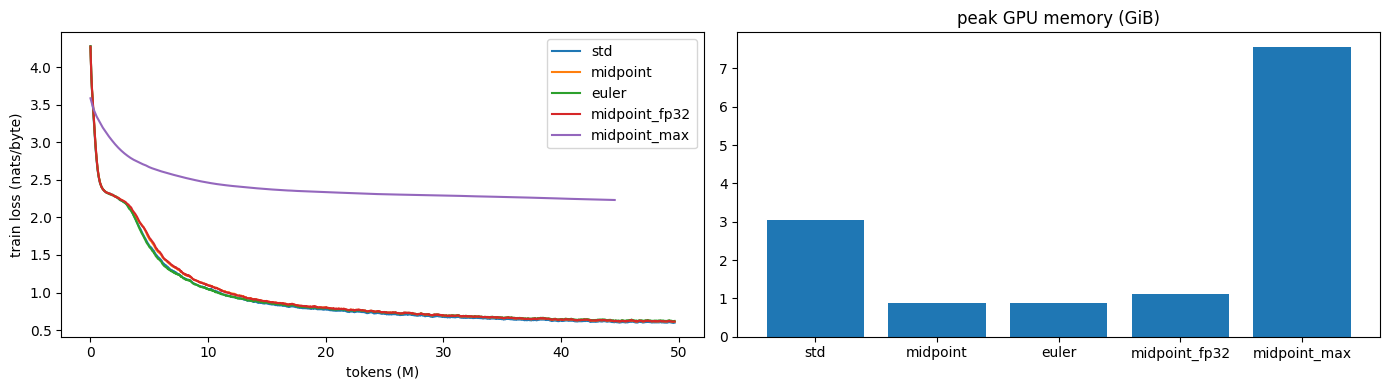

In [12]:
print(f"{'run':15}{'batch':>6}{'steps':>7}{'train':>8}{'val':>8}{'tok/s':>10}{'min':>7}{'peak GiB':>10}{'recon':>10}")
for k, r in R.items():
    print(f"{k:15}{r['batch']:6}{r['steps']:7}{r['train_loss']:8.4f}{r['val_loss']:8.4f}"
          f"{r['tok_s']:10,.0f}{r['minutes']:7.1f}{r['peak_gib']:10.2f}{r['recon']:10.1e}")

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for k, r in R.items():
    c = np.convolve(r["curve"], np.ones(20) / 20, mode="valid")
    ax[0].plot(np.arange(len(c)) * r["batch"] * T / 1e6, c, label=k)
ax[0].set_xlabel("tokens (M)"); ax[0].set_ylabel("train loss (nats/byte)"); ax[0].legend()
ax[1].bar(list(R), [r["peak_gib"] for r in R.values()]); ax[1].set_title("peak GPU memory (GiB)")
plt.tight_layout(); plt.show()

## Findings (generated from the runs)

In [13]:
s, b, bf, mx = R["std"], R[BEST], R[f"{BEST}_fp32"], R[f"{BEST}_max"]
o = "euler" if BEST == "midpoint" else "midpoint"
print(f"1. Variant: {BEST} worked better - val {b['val_loss']:.3f} vs {o} {R[o]['val_loss']:.3f}; "
      f"rebuild error {b['recon']:.1e} vs {R[o]['recon']:.1e}.")
print(f"2. Memory at batch {BATCH}: std {s['peak_gib']:.2f} GiB vs reversible {b['peak_gib']:.2f} GiB "
      f"({s['peak_gib']/b['peak_gib']:.1f}x less).")
print(f"3. Speed cost: {s['tok_s']:,.0f} -> {b['tok_s']:,.0f} tok/s "
      f"({100*(1-b['tok_s']/s['tok_s']):.0f}% slower; extra forward per layer in backward).")
print(f"4. Loss cost at same batch: val {s['val_loss']:.3f} (std) vs {b['val_loss']:.3f} ({BEST}).")
print(f"5. bf16 rebuild error {b['recon']:.1e} -> fp32 blocks {bf['recon']:.1e}; val {bf['val_loss']:.3f}, "
      f"{bf['tok_s']:,.0f} tok/s. Rounding in the rebuilt activations "
      f"{'explains part of' if bf['val_loss'] < b['val_loss'] else 'does not explain'} the loss gap.")
print(f"6. Max batch: std {MAXB_STD} vs {BEST} {MAXB_REV} ({MAXB_REV//MAXB_STD}x), "
      f"peak {mx['peak_gib']:.1f} GiB, {mx['tok_s']:,.0f} tok/s "
      f"({100*(mx['tok_s']/b['tok_s']-1):+.0f}% vs batch {BATCH}).")
print(f"7. Max-batch loss {mx['val_loss']:.3f} is not comparable: same 50M tokens = only {mx['steps']} "
      f"optimizer steps vs {b['steps']}. Bigger batch buys throughput, not sample efficiency, "
      f"unless LR and token budget are rescaled.")

1. Variant: midpoint worked better - val 0.643 vs euler 0.651; rebuild error 9.3e-02 vs 2.7e-01.
2. Memory at batch 32: std 3.04 GiB vs reversible 0.88 GiB (3.5x less).
3. Speed cost: 61,156 -> 46,424 tok/s (24% slower; extra forward per layer in backward).
4. Loss cost at same batch: val 0.631 (std) vs 0.643 (midpoint).
5. bf16 rebuild error 9.3e-02 -> fp32 blocks 1.3e-04; val 0.644, 18,093 tok/s. Rounding in the rebuilt activations does not explain the loss gap.
6. Max batch: std 128 vs midpoint 512 (4x), peak 7.6 GiB, 47,899 tok/s (+3% vs batch 32).
7. Max-batch loss 2.224 is not comparable: same 50M tokens = only 190 optimizer steps vs 3051. Bigger batch buys throughput, not sample efficiency, unless LR and token budget are rescaled.
